### Initialization
Add the Surrogate Modeling module and setup the notebook

In [1]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)


C:\Users\troyz\GitProjects\SurrogateModeling\SurrogateModels


### Kriging Plots

Use the Kriging features from the surrogate modeling module to show kriging on various size data sets

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Optimization terminated successfully.
         Current function value: 4.879240
         Iterations: 24
         Function evaluations: 48
Optimization terminated successfully.
         Current function value: 7.885718
         Iterations: 34
         Function evaluations: 88


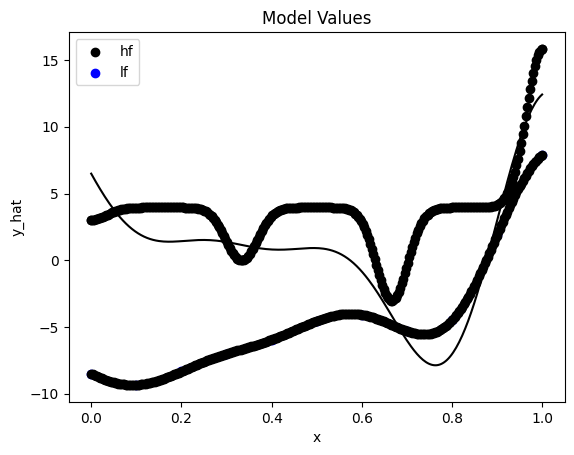

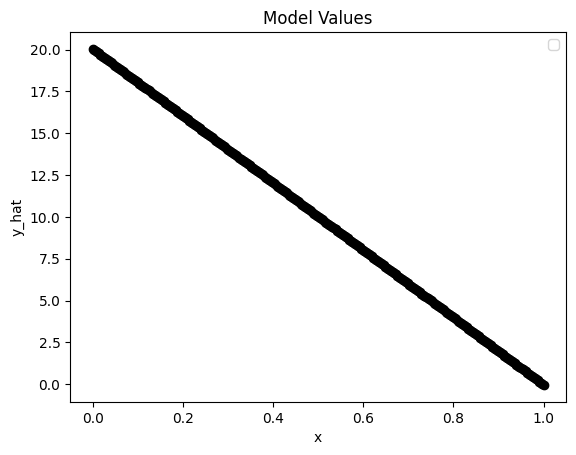

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, cokriging

# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

x_lf = np.zeros((n_lf,dim), dtype=float)
x_hf = np.zeros((n_hf,dim), dtype=float)

x_lf[:,0] = np.linspace(xmin,xmax,n_lf)
y_lf = mfs_functions.cheap_test_function(fxn_ind,x_lf)
x_hf[:,0] = np.linspace(xmin,xmax,n_hf)
y_hf = mfs_functions.expensive_test_function(fxn_ind,x_hf)
model = cokriging.CoKriging(x_lf,y_lf,x_hf,y_hf)

x_vals = np.ones((300,1))
x_vals[:,0] = np.linspace(0,1,300)

model.plot_data("Cokriging Model")
model.plot_model(x_vals,"Cokriging Model")
model.kriging_hf.plot_model(x_vals, "Cokriging Model")
model.kriging_lf.plot_model(x_vals,"Cokriging Model")
model.kriging_diff.plot_model(x_vals,"Diff Model")
plt.show()